In [ ]:
print("Hello! My AI project starts here.")

Hello! My AI project starts here.


In [ ]:
import sys

print("Python version:", sys.version)
print("Project environment is ready!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Project environment is ready!


In [ ]:
import requests

url = "https://images.cocodataset.org/"

try:
    response = requests.get(url, timeout=20)
    print("Status code:", response.status_code)

    if response.status_code == 200:
        print("Connection successful!")
    else:
        print("The website responded, but access may be limited.")
except requests.RequestException as e:
    print("Connection failed:", e)

Connection failed: HTTPSConnectionPool(host='images.cocodataset.org', port=443): Max retries exceeded with url: / (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'images.cocodataset.org'. (_ssl.c:1032)")))


In [ ]:
import requests

url = "https://images.cocodataset.org/"

try:
    response = requests.get(
        "https://www.google.com",
        timeout=15
    )
    print("Internet connection status:", response.status_code)
except requests.RequestException as e:
    print("Connection error:", e)

Internet connection status: 200


In [ ]:
import requests

url = "https://images.cocodataset.org/annotations/annotations_trainval2017.zip"

try:
    response = requests.get(url, stream=True, timeout=20)
    print("Status code:", response.status_code)
    print("Content type:", response.headers.get("Content-Type"))
    print("File size:", response.headers.get("Content-Length"))
    response.close()
except requests.RequestException as e:
    print("Connection error:", e)

Connection error: HTTPSConnectionPool(host='images.cocodataset.org', port=443): Max retries exceeded with url: /annotations/annotations_trainval2017.zip (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'images.cocodataset.org'. (_ssl.c:1032)")))


In [ ]:
import requests

url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

try:
    response = requests.get(url, stream=True, timeout=20)
    print("Status code:", response.status_code)
    print("Final URL:", response.url)
    response.close()
except requests.RequestException as e:
    print("Error:", e)

Status code: 200
Final URL: http://images.cocodataset.org/annotations/annotations_trainval2017.zip


In [ ]:

import requests

url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
output_file = "annotations_trainval2017.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(output_file, "wb") as f:
    f.write(response.content)

print("Download completed!")
print("File size:", round(len(response.content) / (1024**2), 2), "MB")


Download completed!
File size: 241.19 MB


In [ ]:

import zipfile
import os

zip_path = "annotations_trainval2017.zip"
extract_path = "coco_annotations"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Files extracted:")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)


Extraction completed!
Files extracted:
instances_val2017.json
captions_val2017.json
person_keypoints_train2017.json
captions_train2017.json
person_keypoints_val2017.json
instances_train2017.json


In [ ]:

import json
import os

captions_path = os.path.join(
    "coco_annotations",
    "annotations",
    "captions_train2017.json"
)

with open(captions_path, "r", encoding="utf-8") as f:
    captions_data = json.load(f)

print("Number of images:", len(captions_data["images"]))
print("Number of captions:", len(captions_data["annotations"]))

print("\nFirst 5 captions:")
for annotation in captions_data["annotations"][:5]:
    print("-", annotation["caption"])


Number of images: 118287
Number of captions: 591753

First 5 captions:
- A bicycle replica with a clock as the front wheel.
- A room with blue walls and a white sink and door.
- A car that seems to be parked illegally behind a legally parked car
- A large passenger airplane flying through the air.
- There is a GOL plane taking off in a partly cloudy sky.


Total captions: 591753
Missing captions: 0
Exact duplicate captions: 21472

Caption length statistics:
count    591753.00
mean         10.46
std           2.39
min           5.00
25%           9.00
50%          10.00
75%          11.00
max          49.00
Name: word_count, dtype: float64

Vocabulary size: 26446

Top 20 most frequent words:
[('a', 978680), ('on', 215689), ('of', 204072), ('the', 197770), ('in', 184142), ('with', 154811), ('and', 140916), ('is', 98184), ('man', 73340), ('to', 68161), ('sitting', 52911), ('an', 49875), ('two', 48404), ('at', 42724), ('standing', 42485), ('people', 41939), ('are', 41086), ('next', 37215), ('white', 36364), ('woman', 34210)]


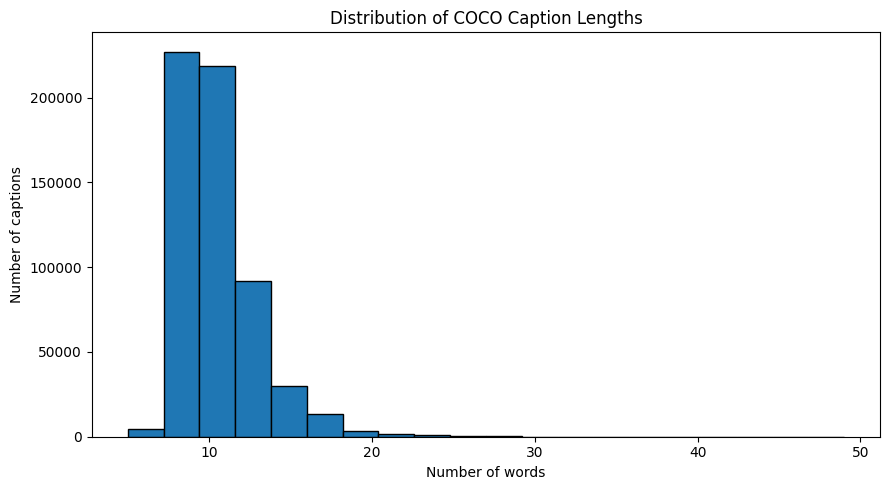

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import re
from collections import Counter

# Extract captions
captions = [
    item["caption"]
    for item in captions_data["annotations"]
]

df = pd.DataFrame({"caption": captions})

# Calculate number of words in each caption
df["word_count"] = df["caption"].apply(
    lambda text: len(text.split())
)

# Basic statistics
print("Total captions:", len(df))
print("Missing captions:", df["caption"].isna().sum())
print("Exact duplicate captions:", df["caption"].duplicated().sum())

print("\nCaption length statistics:")
print(df["word_count"].describe().round(2))

# Vocabulary size and frequent words
all_words = re.findall(
    r"\b[a-z]+\b",
    " ".join(captions).lower()
)

print("\nVocabulary size:", len(set(all_words)))
print("\nTop 20 most frequent words:")
print(Counter(all_words).most_common(20))

# Plot caption length distribution
plt.figure(figsize=(9, 5))
plt.hist(df["word_count"], bins=20, edgecolor="black")
plt.title("Distribution of COCO Caption Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of captions")
plt.tight_layout()
plt.show()


Top 20 content words:
[('man', 73340), ('sitting', 52911), ('two', 48404), ('standing', 42485), ('people', 41939), ('next', 37215), ('white', 36364), ('woman', 34210), ('street', 30291), ('table', 30187), ('holding', 27968), ('person', 24745), ('large', 24556), ('some', 24329), ('down', 23140), ('top', 22299), ('group', 21599), ('up', 21500), ('field', 20779), ('small', 20094)]


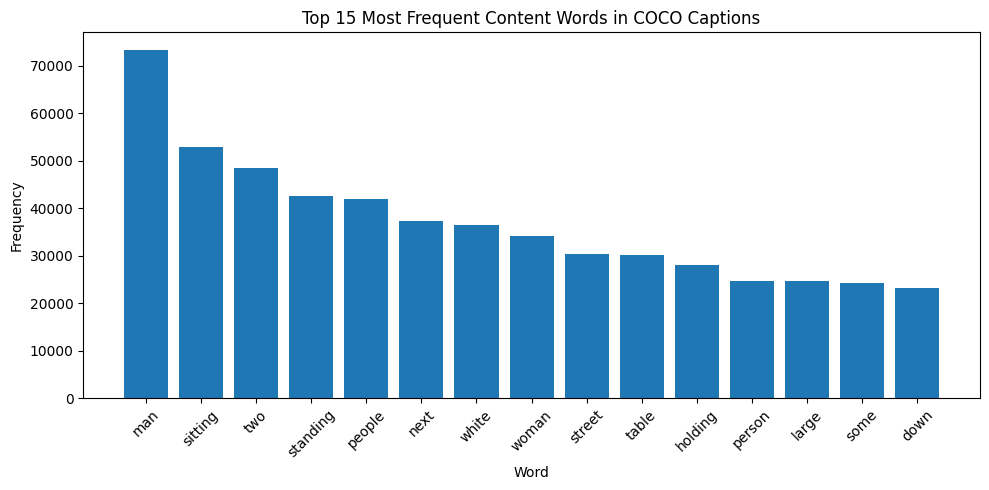

In [ ]:

from collections import Counter
import re
import matplotlib.pyplot as plt

captions = [
    item["caption"]
    for item in captions_data["annotations"]
]

# Remove common English stop words for a clearer content-word analysis
stop_words = {
    "a", "an", "the", "is", "are", "was", "were",
    "in", "on", "at", "of", "to", "with", "and",
    "for", "by", "from", "this", "that", "it", "its"
}

words = re.findall(r"\b[a-z]+\b", " ".join(captions).lower())
content_words = [word for word in words if word not in stop_words]

print("Top 20 content words:")
print(Counter(content_words).most_common(20))

# Plot the 15 most frequent content words
top_words = Counter(content_words).most_common(15)
labels = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(10, 5))
plt.bar(labels, frequencies)
plt.title("Top 15 Most Frequent Content Words in COCO Captions")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Number of annotated images: 118287
Number of object annotations: 860001

Top 20 object classes:
 Object class  Number of instances
       person               262465
          car                43867
        chair                38491
         book                24715
       bottle                24342
          cup                20650
 dining table                15714
         bowl                14358
traffic light                12884
      handbag                12354
     umbrella                11431
         bird                10806
         boat                10759
        truck                 9973
        bench                 9838
        sheep                 9509
       banana                 9458
         kite                 9076
   motorcycle                 8725
     backpack                 8720


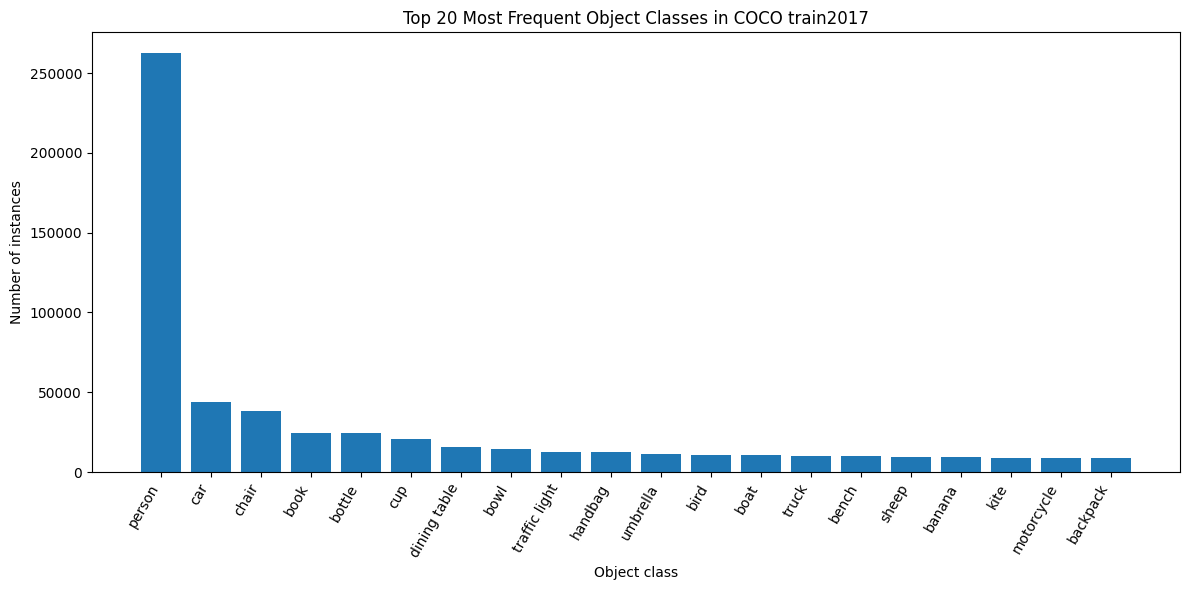


Average annotated objects per image: 7.27


In [ ]:

import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Load COCO object annotations
with open(
    "coco_annotations/annotations/instances_train2017.json",
    "r"
) as f:
    instances_data = json.load(f)

# Map category IDs to object names
category_names = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

# Count object instances by category
object_counts = Counter(
    annotation["category_id"]
    for annotation in instances_data["annotations"]
)

# Display the 20 most frequent object classes
top_objects = [
    (category_names[category_id], count)
    for category_id, count in object_counts.most_common(20)
]

objects_df = pd.DataFrame(
    top_objects,
    columns=["Object class", "Number of instances"]
)

print("Number of annotated images:", len(instances_data["images"]))
print("Number of object annotations:", len(instances_data["annotations"]))
print("\nTop 20 object classes:")
print(objects_df.to_string(index=False))

# Visualize the most frequent object classes
plt.figure(figsize=(12, 6))
plt.bar(
    objects_df["Object class"],
    objects_df["Number of instances"]
)
plt.title("Top 20 Most Frequent Object Classes in COCO train2017")
plt.xlabel("Object class")
plt.ylabel("Number of instances")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

# Calculate average number of annotated objects per image
objects_per_image = Counter(
    annotation["image_id"]
    for annotation in instances_data["annotations"]
)

all_image_ids = [
    image["id"] for image in instances_data["images"]
]

object_numbers = [
    objects_per_image.get(image_id, 0)
    for image_id in all_image_ids
]

print(
    "\nAverage annotated objects per image:",
    round(sum(object_numbers) / len(object_numbers), 2)
)


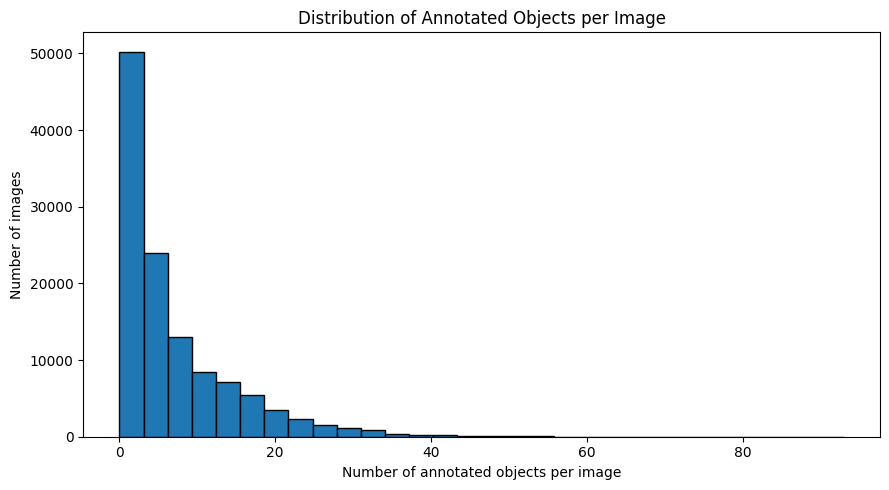

Images with zero annotated objects: 1021
Images with 1-5 objects: 66915
Images with 6-10 objects: 22347
Images with more than 10 objects: 28004


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(object_numbers, bins=30, edgecolor="black")
plt.title("Distribution of Annotated Objects per Image")
plt.xlabel("Number of annotated objects per image")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

print("Images with zero annotated objects:", sum(n == 0 for n in object_numbers))
print("Images with 1-5 objects:", sum(1 <= n <= 5 for n in object_numbers))
print("Images with 6-10 objects:", sum(6 <= n <= 10 for n in object_numbers))
print("Images with more than 10 objects:", sum(n > 10 for n in object_numbers))


In [ ]:

import random
import json
import os

# Make the selection reproducible
random.seed(42)

# Select 10,000 unique image IDs from COCO train2017
all_image_ids = [img["id"] for img in captions_data["images"]]

selected_image_ids = sorted(
    random.sample(all_image_ids, 10_000)
)

selected_ids = set(selected_image_ids)

# Keep the captions belonging to those 10,000 images
selected_captions = [
    caption for caption in captions_data["annotations"]
    if caption["image_id"] in selected_ids
]

# Check the result
print("Selected images:", len(selected_image_ids))
print("Selected captions:", len(selected_captions))
print("Expected captions:", 10_000 * 5)

# Save the selected image IDs and captions
os.makedirs("phase1_data", exist_ok=True)

with open("phase1_data/train_image_ids.json", "w") as f:
    json.dump(selected_image_ids, f)

with open("phase1_data/train_captions.json", "w") as f:
    json.dump(selected_captions, f)

print("Files saved successfully.")


Selected images: 10000
Selected captions: 50026
Expected captions: 50000
Files saved successfully.


In [ ]:
from collections import Counter

caption_counts = Counter(
    caption["image_id"] for caption in selected_captions
)

count_distribution = Counter(caption_counts.values())

print("Caption count distribution:", count_distribution)
print("Images with other than 5 captions:",
      sum(count != 5 for count in caption_counts.values()))

Caption count distribution: Counter({5: 9976, 6: 22, 7: 2})
Images with other than 5 captions: 24


In [ ]:
from collections import defaultdict
import json
import os

# Group captions by image
captions_by_image = defaultdict(list)

for caption in selected_captions:
    captions_by_image[caption["image_id"]].append(caption)

# Keep exactly 5 captions per image
selected_captions_5 = []

for image_id in selected_image_ids:
    image_captions = captions_by_image[image_id]
    selected_captions_5.extend(image_captions[:5])

print("Selected images:", len(selected_image_ids))
print("Selected captions:", len(selected_captions_5))
print("Expected captions:", len(selected_image_ids) * 5)

# Save corrected captions
os.makedirs("phase1_data", exist_ok=True)

with open("phase1_data/train_captions.json", "w") as f:
    json.dump(selected_captions_5, f)

print("Corrected captions saved successfully!")

Selected images: 10000
Selected captions: 50000
Expected captions: 50000
Corrected captions saved successfully!


In [ ]:

from collections import Counter

# selected_image_ids already contains integer IDs
image_ids = selected_image_ids

caption_counts = Counter(
    caption["image_id"] for caption in selected_captions_5
)

# Check caption integrity
missing_caption_images = [
    image_id for image_id in image_ids
    if caption_counts[image_id] == 0
]

wrong_caption_count = [
    image_id for image_id in image_ids
    if caption_counts[image_id] != 5
]

# Check duplicate image IDs
duplicate_image_ids = len(image_ids) - len(set(image_ids))

# Check whether selected IDs exist in COCO metadata
available_ids = {
    img["id"] for img in captions_data["images"]
}

unknown_ids = [
    image_id for image_id in image_ids
    if image_id not in available_ids
]

print("=== TRAINING DATA AUDIT ===")
print("Selected images:", len(image_ids))
print("Unique image IDs:", len(set(image_ids)))
print("Total captions:", len(selected_captions_5))
print("Images without captions:", len(missing_caption_images))
print("Images not having exactly 5 captions:", len(wrong_caption_count))
print("Duplicate image IDs:", duplicate_image_ids)
print("Image IDs missing from COCO metadata:", len(unknown_ids))


=== TRAINING DATA AUDIT ===
Selected images: 10000
Unique image IDs: 10000
Total captions: 50000
Images without captions: 0
Images not having exactly 5 captions: 0
Duplicate image IDs: 0
Image IDs missing from COCO metadata: 0


In [ ]:

from collections import Counter

# 1. Check selected image IDs
image_ids = selected_image_ids

# 2. Count captions per image
caption_counts = Counter(
    caption["image_id"]
    for caption in selected_captions_5
)

# 3. Check data integrity
missing_caption_images = [
    image_id for image_id in image_ids
    if caption_counts[image_id] == 0
]

wrong_caption_count = [
    image_id for image_id in image_ids
    if caption_counts[image_id] != 5
]

duplicate_image_ids = len(image_ids) - len(set(image_ids))

available_ids = {
    img["id"] for img in captions_data["images"]
}

unknown_ids = [
    image_id for image_id in image_ids
    if image_id not in available_ids
]

# 4. Display results
print("=== TRAINING DATA AUDIT ===")
print("Selected images:", len(image_ids))
print("Unique image IDs:", len(set(image_ids)))
print("Total captions:", len(selected_captions_5))
print("Images without captions:", len(missing_caption_images))
print("Images not having exactly 5 captions:", len(wrong_caption_count))
print("Duplicate image IDs:", duplicate_image_ids)
print("Image IDs missing from COCO metadata:", len(unknown_ids))


=== TRAINING DATA AUDIT ===
Selected images: 10000
Unique image IDs: 10000
Total captions: 50000
Images without captions: 0
Images not having exactly 5 captions: 0
Duplicate image IDs: 0
Image IDs missing from COCO metadata: 0


In [ ]:

import random
import json
import os

# Use a fixed seed for reproducibility
random.seed(42)

# Training image IDs already selected
train_ids = set(selected_image_ids)

# Find images not used for training
remaining_ids = [
    img["id"]
    for img in captions_data["images"]
    if img["id"] not in train_ids
]

# Select 100 different validation images
validation_ids = sorted(random.sample(remaining_ids, 100))

# Verify the split
assert len(validation_ids) == 100
assert len(set(validation_ids)) == 100
assert train_ids.isdisjoint(set(validation_ids))

# Save validation IDs
os.makedirs("phase1_data", exist_ok=True)

with open(
    "phase1_data/validation_image_ids.json", "w"
) as f:
    json.dump(validation_ids, f, indent=2)

print("Training images:", len(train_ids))
print("Validation images:", len(validation_ids))
print("Overlap:", len(train_ids.intersection(set(validation_ids))))
print("Validation IDs saved successfully!")


Training images: 10000
Validation images: 100
Overlap: 0
Validation IDs saved successfully!


In [ ]:

import os

print("Current project files:")

for folder, subfolders, files in os.walk("/content/phase1_data"):
    for filename in files:
        path = os.path.join(folder, filename)
        print(filename, "-", round(os.path.getsize(path) / 1024, 1), "KB")


Current project files:


In [ ]:

import os

print("Does phase1_data exist?", os.path.exists("/content/phase1_data"))
print("Files in /content:")

for item in os.listdir("/content"):
    print(item)


Does phase1_data exist? False
Files in /content:
.config
sample_data


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

print("Google Drive connected:", os.path.exists("/content/drive/MyDrive"))

for folder, subfolders, files in os.walk("/content/drive/MyDrive"):
    for filename in files:
        if filename in [
            "train_captions.json",
            "validation_image_ids.json",
            "captions_train2017.json",
            "annotations_trainval2017.zip"
        ]:
            print(os.path.join(folder, filename))


Google Drive connected: True


In [ ]:

import os

target_files = {
    "train_captions.json",
    "validation_image_ids.json",
    "captions_train2017.json",
    "annotations_trainval2017.zip"
}

for folder, subfolders, files in os.walk("/content/drive/MyDrive"):
    for filename in files:
        if filename in target_files:
            print(os.path.join(folder, filename))


In [ ]:

import os

target_files = {
    "train_captions.json",
    "validation_image_ids.json",
    "captions_train2017.json",
    "annotations_trainval2017.zip"
}

for folder, subfolders, files in os.walk("/content/drive/MyDrive"):
    for filename in files:
        if filename in target_files:
            print(os.path.join(folder, filename))


In [ ]:

import os
import requests

url = "https://images.cocodataset.org/zips/val2017.zip"
zip_path = "/content/val2017.zip"

if not os.path.exists(zip_path):
    print("Downloading COCO val2017 images...")

    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Download completed successfully!")
else:
    print("The ZIP file already exists.")

print("File size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))


SSLError: HTTPSConnectionPool(host='images.cocodataset.org', port=443): Max retries exceeded with url: /zips/val2017.zip (Caused by SSLError(SSLCertVerificationError(1, "[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'images.cocodataset.org'. (_ssl.c:1032)")))

In [ ]:

import os
import requests

url = "http://images.cocodataset.org/zips/val2017.zip"
zip_path = "/content/val2017.zip"

print("Checking COCO image archive...")

response = requests.get(
    url,
    stream=True,
    timeout=60,
    allow_redirects=True
)
response.raise_for_status()

with open(zip_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Download finished!")
print("Final URL:", response.url)
print("File size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))


Checking COCO image archive...
Download finished!
Final URL: http://images.cocodataset.org/zips/val2017.zip
File size (GB): 0.82


In [ ]:
import os
import zipfile

zip_path = "/content/val2017.zip"

print("File exists:", os.path.exists(zip_path))
print("File size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP integrity check...")
    bad_file = z.testzip()

    if bad_file is None:
        print("ZIP is valid!")
    else:
        print("Corrupted file:", bad_file)

File exists: True
File size (GB): 0.82
ZIP integrity check...
ZIP is valid!


In [ ]:
import json
import random
import os

# Load COCO validation captions
val_captions_path = "coco_annotations/annotations/captions_val2017.json"

with open(val_captions_path, "r") as f:
    val_data = json.load(f)

# Get all available validation image IDs
all_val_ids = sorted([
    image["id"] for image in val_data["images"]
])

# Select 100 test images reproducibly
random.seed(123)
test_ids = random.sample(all_val_ids, 100)
test_ids = sorted(test_ids)

# Save selected test IDs
os.makedirs("phase1_data", exist_ok=True)

with open("phase1_data/test_image_ids.json", "w") as f:
    json.dump(test_ids, f, indent=2)

print("Available validation images:", len(all_val_ids))
print("Selected test images:", len(test_ids))
print("Unique test IDs:", len(set(test_ids)))
print("Test IDs saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'coco_annotations/annotations/captions_val2017.json'

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file in [
            "captions_val2017.json",
            "captions_train2017.json",
            "annotations_trainval2017.zip"
        ]:
            print(os.path.join(root, file))

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir("."))

print("\nFiles in /content:")
print(os.listdir("/content"))

print("\nGoogle Drive mounted?")
print(os.path.exists("/content/drive/MyDrive"))

Current folder: /content

Files in current folder:
['.config', 'val2017.zip', 'drive', 'sample_data']

Files in /content:
['.config', 'val2017.zip', 'drive', 'sample_data']

Google Drive mounted?
True


In [ ]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file in [
            "annotations_trainval2017.zip",
            "captions_val2017.json",
            "captions_train2017.json"
        ]:
            print(os.path.join(root, file))

In [ ]:
import os

drive_path = "/content/drive/MyDrive"

print("MyDrive folders and files:")
for item in os.listdir(drive_path):
    print(item)

MyDrive folders and files:
Colab Notebooks
Classroom
file.pdf
Corrigé_-Série_3-_.pdf
Scm
CamScanner 07-01-2025 13.19.pdf
inbound5936125084060289746.jpg
inbound1278638706209976293.jpg
4_6017152239989171260.pdf
CamScanner 16-10-2025 22.19.pdf
sandjak_Roumaissa_groupe3.zip
CamScanner 08-11-2025 16.42.pdf
tp GL.rtf
IMG_20251127_214411.jpg
Installer flex bison sous Windows.gvid
photo_2026-01-21_16-16-44 (1).jpg
photo_2026-01-21_16-16-44.jpg
photo_2026-01-21_16-16-55.jpg
photo_2026-01-26_19-01-23 (2).jpg
photo_2026-01-26_19-01-23 (1).jpg
photo_2026-01-26_19-01-23.jpg
photo_2026-01-26_19-01-30.jpg
photo_2026-02-13_18-44-26.jpg
memoire_de_licence (12) (1).pdf
memoire_de_licence (12) (1).gdoc
licence cs.zip
Diagramme sans nom (3).drawio.png
Diagramme sans nom (2).drawio.png
uml.drawio.png
Diagramme sans nom.drawio.pdf
Diagramme sans nom (1).drawio.png
Diagramme sans nom.drawio.png
Mini Projet IA_En_Fr.gdoc
Diagramme sans nom.drawio
sequance VIEW DASHBOARD.drawio.png
Sandjak Roumaissa.zip
memo

In [ ]:
import os

folder = "/content/drive/MyDrive/Colab Notebooks"

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith(".zip") or file in [
            "captions_val2017.json",
            "captions_train2017.json"
        ]:
            print(os.path.join(root, file))

In [ ]:
import os
import requests
import zipfile

url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
zip_path = "/content/annotations_trainval2017.zip"

if not os.path.exists(zip_path):
    print("Downloading annotations...")
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print("Download complete:", os.path.getsize(zip_path) / 1e6, "MB")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Validation captions available:",
          "annotations/captions_val2017.json" in z.namelist())

Download complete: 252.907541 MB
Validation captions available: True


In [ ]:
import os
import json
import zipfile
import random

zip_path = "/content/annotations_trainval2017.zip"
captions_path = "/content/captions_val2017.json"

# Extract only the validation captions JSON
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open("annotations/captions_val2017.json") as source:
        with open(captions_path, "wb") as target:
            target.write(source.read())

# Load validation annotations
with open(captions_path, "r") as f:
    val_data = json.load(f)

# Select 100 unique test image IDs
all_val_ids = sorted(image["id"] for image in val_data["images"])

random.seed(123)
test_ids = sorted(random.sample(all_val_ids, 100))

# Save test IDs
os.makedirs("/content/phase1_data", exist_ok=True)

with open("/content/phase1_data/test_image_ids.json", "w") as f:
    json.dump(test_ids, f, indent=2)

print("Available validation images:", len(all_val_ids))
print("Selected test images:", len(test_ids))
print("Unique test IDs:", len(set(test_ids)))
print("Test IDs saved successfully!")

Available validation images: 5000
Selected test images: 100
Unique test IDs: 100
Test IDs saved successfully!


In [ ]:

import os
import requests

url = "https://images.cocodataset.org/zips/val2017.zip"
zip_path = "/content/val2017.zip"

if not os.path.exists(zip_path):
    print("Downloading COCO val2017 images...")

    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Download completed!")
else:
    print("val2017.zip already exists.")

print("File size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))


val2017.zip already exists.
File size (GB): 0.82


In [ ]:

import os
import json
import random
import zipfile

zip_path = "/content/val2017.zip"

# Read image filenames inside the archive without extracting everything
with zipfile.ZipFile(zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.startswith("val2017/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

# COCO filenames look like: val2017/000000123456.jpg
val_image_ids = sorted([
    int(os.path.splitext(os.path.basename(name))[0])
    for name in image_files
])

print("Images available in val2017:", len(val_image_ids))

# Select 100 test images reproducibly
random.seed(42)
test_ids = sorted(random.sample(val_image_ids, 100))

# Save selected test IDs
os.makedirs("/content/phase1_data", exist_ok=True)

with open("/content/phase1_data/test_image_ids.json", "w") as f:
    json.dump(test_ids, f, indent=2)

print("Test images selected:", len(test_ids))
print("First 10 test IDs:", test_ids[:10])


Images available in val2017: 5000
Test images selected: 100
First 10 test IDs: [5529, 21167, 22705, 25228, 27620, 27768, 39405, 41990, 51738, 61418]


In [ ]:
import os
import zipfile

zip_path = "/content/val2017.zip"
test_images_dir = "/content/phase1_data/test_images"

os.makedirs(test_images_dir, exist_ok=True)

with open("/content/phase1_data/test_image_ids.json", "r") as f:
    test_ids = json.load(f)

with zipfile.ZipFile(zip_path, "r") as z:
    extracted = 0

    for image_id in test_ids:
        filename = f"val2017/{image_id:012d}.jpg"

        if filename in z.namelist():
            z.extract(filename, "/content/temp_coco")
            source = f"/content/temp_coco/{filename}"
            destination = os.path.join(
                test_images_dir, f"{image_id:012d}.jpg"
            )
            os.replace(source, destination)
            extracted += 1

print("Test images extracted:", extracted)
print("Images in test folder:", len(os.listdir(test_images_dir)))

Test images extracted: 100
Images in test folder: 100


In [ ]:
import os
import json

# Find the validation captions annotation file
captions_path = None

for root, dirs, files in os.walk("/content"):
    if "captions_val2017.json" in files:
        captions_path = os.path.join(root, "captions_val2017.json")
        break

if captions_path is None:
    print("captions_val2017.json not found.")
    print("We need to locate or extract the COCO annotations ZIP.")
else:
    print("Captions file found:", captions_path)

    with open(captions_path, "r") as f:
        val_captions_data = json.load(f)

    with open("/content/phase1_data/test_image_ids.json", "r") as f:
        test_ids = set(json.load(f))

    # Keep original reference captions for test images
    test_references = {}

    for annotation in val_captions_data["annotations"]:
        image_id = annotation["image_id"]

        if image_id in test_ids:
            test_references.setdefault(str(image_id), []).append(
                annotation["caption"]
            )

    # Audit the references
    print("Test images:", len(test_ids))
    print("Images with reference captions:", len(test_references))
    print(
        "Total reference captions:",
        sum(len(caps) for caps in test_references.values())
    )
    print(
        "Images without references:",
        len(test_ids - {int(i) for i in test_references})
    )

    # Save separately from the retrieval knowledge base
    output_path = "/content/phase1_data/test_reference_captions.json"

    with open(output_path, "w") as f:
        json.dump(test_references, f, indent=2)

    print("Saved references to:", output_path)

Captions file found: /content/captions_val2017.json
Test images: 100
Images with reference captions: 100
Total reference captions: 501
Images without references: 0
Saved references to: /content/phase1_data/test_reference_captions.json


Number of test images: 100
First 5 images verified successfully!


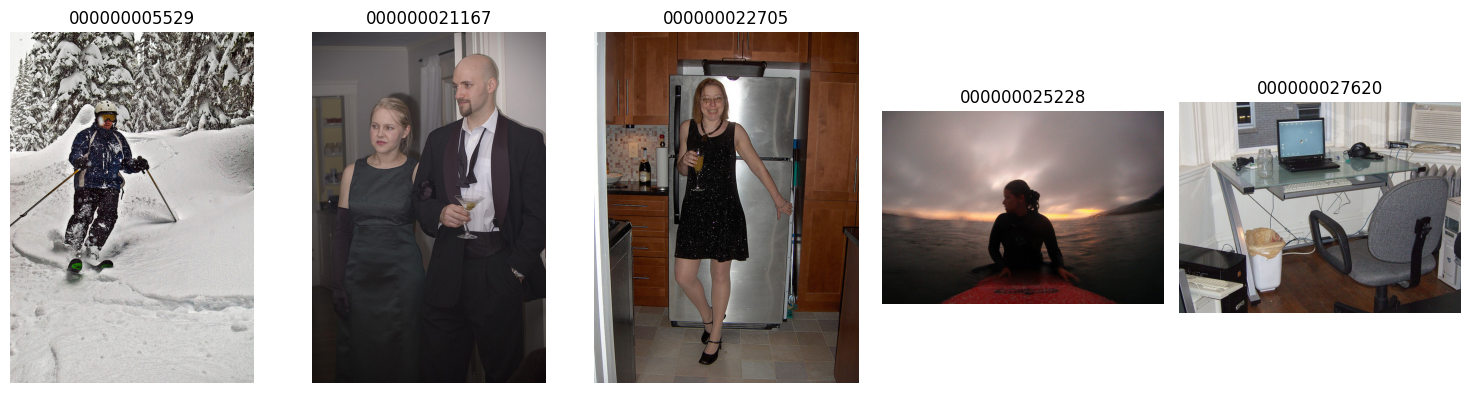

In [ ]:
from PIL import Image
import os
import matplotlib.pyplot as plt

test_images_dir = "/content/phase1_data/test_images"

image_files = sorted([
    f for f in os.listdir(test_images_dir)
    if f.lower().endswith(".jpg")
])

print("Number of test images:", len(image_files))

# Check that the first 5 images can be opened
for filename in image_files[:5]:
    path = os.path.join(test_images_dir, filename)

    with Image.open(path) as img:
        img.verify()

print("First 5 images verified successfully!")

# Display the first 5 images
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, filename in zip(axes, image_files[:5]):
    path = os.path.join(test_images_dir, filename)

    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(filename.replace(".jpg", ""))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

for path in [
    "/content/phase1_data/train_captions.json",
    "/content/phase1_data/validation_image_ids.json",
    "/content/phase1_data/test_image_ids.json",
    "/content/phase1_data/test_reference_captions.json",
    "/content/val2017.zip",
    "/content/captions_train2017.json",
    "/content/captions_val2017.json",
]:
    print(f"{'EXISTS' if os.path.exists(path) else 'MISSING'}: {path}")

MISSING: /content/phase1_data/train_captions.json
MISSING: /content/phase1_data/validation_image_ids.json
EXISTS: /content/phase1_data/test_image_ids.json
EXISTS: /content/phase1_data/test_reference_captions.json
EXISTS: /content/val2017.zip
MISSING: /content/captions_train2017.json
EXISTS: /content/captions_val2017.json


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for filename in files:
        if filename == "annotations_trainval2017.zip":
            print("Found:", os.path.join(root, filename))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, json, random, zipfile, requests
from collections import defaultdict

OUT = "/content/drive/MyDrive/phase1_data"
os.makedirs(OUT, exist_ok=True)

zip_path = "/content/annotations_trainval2017.zip"
if not os.path.exists(zip_path):
    r = requests.get("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                     stream=True, timeout=60)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for ch in r.iter_content(1 << 20):
            f.write(ch)

with zipfile.ZipFile(zip_path) as z:
    train = json.load(z.open("annotations/captions_train2017.json"))

all_ids = [im["id"] for im in train["images"]]

random.seed(42)
train_ids = sorted(random.sample(all_ids, 10000))
train_set = set(train_ids)
remaining = [i for i in all_ids if i not in train_set]
random.seed(42)
val_ids = sorted(random.sample(remaining, 100))
assert train_set.isdisjoint(val_ids)

by_img = defaultdict(list)
for a in train["annotations"]:
    by_img[a["image_id"]].append(a)

train_caps = [a for i in train_ids for a in by_img[i][:5]]
val_caps = [a for i in val_ids for a in by_img[i][:5]]

for name, obj in [("train_image_ids", train_ids), ("train_captions", train_caps),
                  ("validation_image_ids", val_ids), ("validation_captions", val_caps)]:
    json.dump(obj, open(f"{OUT}/{name}.json", "w"))

print(len(train_ids), len(train_caps), len(val_ids), len(val_caps))

10000 50000 100 500


In [ ]:
import os, json, hashlib
from PIL import Image, ImageOps
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))  # لازم تكون منسوخة في Drive

# 1. Leakage audit
assert not set(train_ids) & set(val_ids)
assert not set(train_ids) & set(test_ids)
assert not set(val_ids) & set(test_ids)
print("No overlap between splits ✅")

# 2. Image audit
def audit(folder, ids):
    missing, corrupt, dups, hashes = [], [], [], {}
    for i in tqdm(ids, desc=folder):
        p = f"{BASE}/{folder}/{i:012d}.jpg"
        if not os.path.exists(p):
            missing.append(i); continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                ImageOps.exif_transpose(im).convert("RGB")
        except Exception:
            corrupt.append(i); continue
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h in hashes:
            dups.append([i, hashes[h]])
        else:
            hashes[h] = i
    return {"checked": len(ids), "missing": missing,
            "corrupt": corrupt, "duplicates": dups}

report = {
    "train_images": audit("train_images", train_ids),
    "validation_images": audit("validation_images", val_ids),
    "test_images": audit("test_images", test_ids),
}

for k, v in report.items():
    print(k, "| missing:", len(v["missing"]),
          "| corrupt:", len(v["corrupt"]),
          "| duplicates:", len(v["duplicates"]))

json.dump(report, open(f"{BASE}/audit_report.json", "w"), indent=2)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/test_image_ids.json'

In [ ]:
import os, json, random, zipfile, requests
from collections import defaultdict

BASE = "/content/drive/MyDrive/phase1_data"
os.makedirs(f"{BASE}/test_images", exist_ok=True)

# 1. annotations
zip_path = "/content/annotations_trainval2017.zip"
if not os.path.exists(zip_path):
    r = requests.get("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                     stream=True, timeout=60)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for ch in r.iter_content(1 << 20):
            f.write(ch)

with zipfile.ZipFile(zip_path) as z:
    val = json.load(z.open("annotations/captions_val2017.json"))

# 2. test IDs (نفس seed=42 كيما قبل)
all_val_ids = sorted(im["id"] for im in val["images"])
random.seed(42)
test_ids = sorted(random.sample(all_val_ids, 100))
json.dump(test_ids, open(f"{BASE}/test_image_ids.json", "w"), indent=2)
print("First IDs:", test_ids[:5])   # لازم [5529, 21167, 22705, 25228, 27620]

# 3. reference captions (5 لكل صورة) في ملف منفصل
test_set = set(test_ids)
refs = defaultdict(list)
for a in val["annotations"]:
    if a["image_id"] in test_set and len(refs[str(a["image_id"])]) < 5:
        refs[str(a["image_id"])].append(a["caption"])
json.dump(refs, open(f"{BASE}/test_reference_captions.json", "w"), indent=2)
print("Images:", len(refs), "| Captions:", sum(len(v) for v in refs.values()))

# 4. صور الـ test
for i in test_ids:
    name = f"{i:012d}.jpg"
    path = f"{BASE}/test_images/{name}"
    if not os.path.exists(path):
        r = requests.get(f"http://images.cocodataset.org/val2017/{name}", timeout=30)
        r.raise_for_status()
        open(path, "wb").write(r.content)
print("Test images:", len(os.listdir(f"{BASE}/test_images")))

First IDs: [5529, 21167, 22705, 25228, 27620]
Images: 100 | Captions: 500
Test images: 100


In [ ]:
import os, json, hashlib
from PIL import Image, ImageOps
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))  # لازم تكون منسوخة في Drive

# 1. Leakage audit
assert not set(train_ids) & set(val_ids)
assert not set(train_ids) & set(test_ids)
assert not set(val_ids) & set(test_ids)
print("No overlap between splits ✅")

# 2. Image audit
def audit(folder, ids):
    missing, corrupt, dups, hashes = [], [], [], {}
    for i in tqdm(ids, desc=folder):
        p = f"{BASE}/{folder}/{i:012d}.jpg"
        if not os.path.exists(p):
            missing.append(i); continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                ImageOps.exif_transpose(im).convert("RGB")
        except Exception:
            corrupt.append(i); continue
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h in hashes:
            dups.append([i, hashes[h]])
        else:
            hashes[h] = i
    return {"checked": len(ids), "missing": missing,
            "corrupt": corrupt, "duplicates": dups}

report = {
    "train_images": audit("train_images", train_ids),
    "validation_images": audit("validation_images", val_ids),
    "test_images": audit("test_images", test_ids),
}

for k, v in report.items():
    print(k, "| missing:", len(v["missing"]),
          "| corrupt:", len(v["corrupt"]),
          "| duplicates:", len(v["duplicates"]))

json.dump(report, open(f"{BASE}/audit_report.json", "w"), indent=2)

No overlap between splits ✅


test_images: 100%|██████████| 100/100 [00:01<00:00, 75.26it/s]


train_images | missing: 10000 | corrupt: 0 | duplicates: 0
validation_images | missing: 100 | corrupt: 0 | duplicates: 0
test_images | missing: 0 | corrupt: 0 | duplicates: 0


In [ ]:
import os, json
from concurrent.futures import ThreadPoolExecutor
import requests
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
ids = {
    "train_images": json.load(open(f"{BASE}/train_image_ids.json")),
    "validation_images": json.load(open(f"{BASE}/validation_image_ids.json")),
}
for folder in ids:
    os.makedirs(f"{BASE}/{folder}", exist_ok=True)

def download(args):
    folder, image_id = args
    name = f"{image_id:012d}.jpg"
    path = f"{BASE}/{folder}/{name}"
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return None
    for _ in range(3):
        try:
            r = requests.get(f"http://images.cocodataset.org/train2017/{name}", timeout=30)
            r.raise_for_status()
            open(path, "wb").write(r.content)
            return None
        except Exception:
            pass
    return (folder, image_id)

jobs = [(f, i) for f, lst in ids.items() for i in lst]
with ThreadPoolExecutor(max_workers=16) as ex:
    failed = [r for r in tqdm(ex.map(download, jobs), total=len(jobs)) if r]

print("Failed:", len(failed))

100%|██████████| 10100/10100 [02:28<00:00, 67.80it/s]

Failed: 0


In [ ]:
import os
BASE = "/content/drive/MyDrive/phase1_data"
for folder in ["train_images", "validation_images", "test_images"]:
    print(folder, len(os.listdir(f"{BASE}/{folder}")))

train_images 10000
validation_images 100
test_images 100


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
BASE = "/content/drive/MyDrive/phase1_data"
for f in ["train_images", "validation_images", "test_images"]:
    print(f, len(os.listdir(f"{BASE}/{f}")))

train_images 10000
validation_images 100
test_images 100


In [ ]:
import os, json, hashlib
from PIL import Image, ImageOps
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))

assert not set(train_ids) & set(val_ids)
assert not set(train_ids) & set(test_ids)
assert not set(val_ids) & set(test_ids)
print("No overlap between splits ✅")

def audit(folder, ids):
    missing, corrupt, dups, hashes = [], [], [], {}
    for i in tqdm(ids, desc=folder):
        p = f"{BASE}/{folder}/{i:012d}.jpg"
        if not os.path.exists(p):
            missing.append(i); continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                ImageOps.exif_transpose(im).convert("RGB")
        except Exception:
            corrupt.append(i); continue
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h in hashes:
            dups.append([i, hashes[h]])
        else:
            hashes[h] = i
    return {"checked": len(ids), "missing": missing,
            "corrupt": corrupt, "duplicates": dups}

report = {
    "train_images": audit("train_images", train_ids),
    "validation_images": audit("validation_images", val_ids),
    "test_images": audit("test_images", test_ids),
}

for k, v in report.items():
    print(k, "| missing:", len(v["missing"]),
          "| corrupt:", len(v["corrupt"]),
          "| duplicates:", len(v["duplicates"]))

json.dump(report, open(f"{BASE}/audit_report.json", "w"), indent=2)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/train_image_ids.json'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/phase1_data"
print(os.path.exists(BASE))
print(os.listdir(BASE))

Mounted at /content/drive
True
['train_image_ids.json', 'train_captions.json', 'validation_image_ids.json', 'validation_captions.json', 'test_images', 'test_image_ids.json', 'test_reference_captions.json', 'audit_report.json', 'train_images', 'validation_images']


In [ ]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
report = json.load(open(f"{BASE}/audit_report.json"))
for k, v in report.items():
    print(k, "| checked:", v["checked"],
          "| missing:", len(v["missing"]),
          "| corrupt:", len(v["corrupt"]),
          "| duplicates:", len(v["duplicates"]))

train_images | checked: 10000 | missing: 10000 | corrupt: 0 | duplicates: 0
validation_images | checked: 100 | missing: 100 | corrupt: 0 | duplicates: 0
test_images | checked: 100 | missing: 0 | corrupt: 0 | duplicates: 0


In [ ]:
import os, json, hashlib
from PIL import Image, ImageOps
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))

assert not set(train_ids) & set(val_ids)
assert not set(train_ids) & set(test_ids)
assert not set(val_ids) & set(test_ids)
print("No overlap between splits ✅")

def audit(folder, ids):
    missing, corrupt, dups, hashes = [], [], [], {}
    for i in tqdm(ids, desc=folder):
        p = f"{BASE}/{folder}/{i:012d}.jpg"
        if not os.path.exists(p):
            missing.append(i); continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                ImageOps.exif_transpose(im).convert("RGB")
        except Exception:
            corrupt.append(i); continue
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        if h in hashes:
            dups.append([i, hashes[h]])
        else:
            hashes[h] = i
    return {"checked": len(ids), "missing": missing,
            "corrupt": corrupt, "duplicates": dups}

report = {
    "train_images": audit("train_images", train_ids),
    "validation_images": audit("validation_images", val_ids),
    "test_images": audit("test_images", test_ids),
}

for k, v in report.items():
    print(k, "| missing:", len(v["missing"]),
          "| corrupt:", len(v["corrupt"]),
          "| duplicates:", len(v["duplicates"]))

json.dump(report, open(f"{BASE}/audit_report.json", "w"), indent=2)

No overlap between splits ✅


test_images: 100%|██████████| 100/100 [00:26<00:00,  3.74it/s]

train_images | missing: 0 | corrupt: 0 | duplicates: 1
validation_images | missing: 0 | corrupt: 0 | duplicates: 0
test_images | missing: 0 | corrupt: 0 | duplicates: 0


In [ ]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
report = json.load(open(f"{BASE}/audit_report.json"))

note = {
    "audit_date": "2026-10-25",
    "method": "MD5 file hash comparison",
    "train_images": {"checked": report["train_images"]["checked"],
                     "missing": len(report["train_images"]["missing"]),
                     "corrupt": len(report["train_images"]["corrupt"]),
                     "duplicate_pairs": report["train_images"]["duplicates"]},
    "validation_images": {"duplicates": len(report["validation_images"]["duplicates"])},
    "test_images": {"duplicates": len(report["test_images"]["duplicates"])},
    "action_taken": "none yet: duplicate documented, no image removed",
    "leakage_audit": "no overlap between train, validation and test IDs"
}
json.dump(note, open(f"{BASE}/audit_documentation.json", "w"), indent=2)
print(json.dumps(note, indent=2))

{
  "audit_date": "2026-10-25",
  "method": "MD5 file hash comparison",
  "train_images": {
    "checked": 10000,
    "missing": 0,
    "corrupt": 0,
    "duplicate_pairs": [
      [
        531721,
        438867
      ]
    ]
  },
  "validation_images": {
    "duplicates": 0
  },
  "test_images": {
    "duplicates": 0
  },
  "action_taken": "none yet: duplicate documented, no image removed",
  "leakage_audit": "no overlap between train, validation and test IDs"
}


In [ ]:
import json
from PIL import Image
from collections import Counter
from tqdm import tqdm

BASE = "/content/drive/MyDrive/phase1_data"
ids = json.load(open(f"{BASE}/train_image_ids.json"))

modes, rotated, sizes = Counter(), 0, []
for i in tqdm(ids):
    with Image.open(f"{BASE}/train_images/{i:012d}.jpg") as im:
        modes[im.mode] += 1
        if im.getexif().get(274, 1) != 1:   # 274 = اتجاه الصورة
            rotated += 1
        sizes.append(im.size)

print("Modes:", dict(modes))
print("Images needing EXIF rotation:", rotated)
print("Min size:", min(sizes), "| Max size:", max(sizes))

100%|██████████| 10000/10000 [00:19<00:00, 501.72it/s]

Modes: {'RGB': 9979, 'L': 21}
Images needing EXIF rotation: 0
Min size: (72, 51) | Max size: (640, 640)


In [ ]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
note = {
    "images_inspected": 10000,
    "color_modes": {"RGB": 9979, "L_grayscale": 21},
    "exif_rotation_needed": 0,
    "min_size": [72, 51],
    "max_size": [640, 640],
    "planned_processing": "convert all images to RGB, apply EXIF transpose, resize and normalise with the image encoder's own processor at embedding time"
}
json.dump(note, open(f"{BASE}/image_preprocessing_report.json", "w"), indent=2)
print("saved")

saved


In [ ]:
import json, re
BASE = "/content/drive/MyDrive/phase1_data"

def clean(text):
    t = text.lower().strip()
    t = re.sub(r"[^a-z0-9\s']", " ", t)   # remove punctuation
    return re.sub(r"\s+", " ", t).strip()  # clean extra spaces

for split in ["train", "validation"]:
    caps = json.load(open(f"{BASE}/{split}_captions.json"))
    out = [{"image_id": c["image_id"],
            "caption_id": c["id"],
            "caption_raw": c["caption"],
            "caption_clean": clean(c["caption"])}
           for c in caps]
    json.dump(out, open(f"{BASE}/{split}_captions_processed.json", "w"), indent=1)
    print(split, len(out), "|", out[0]["caption_raw"], "→", out[0]["caption_clean"])

train 50000 | Woman in swim suit holding parasol on sunny day. → woman in swim suit holding parasol on sunny day
validation 500 | A truck with a horse trailer attached to it with horses on top of it. → a truck with a horse trailer attached to it with horses on top of it


In [ ]:
import os, json, zipfile, requests
from collections import defaultdict, Counter

BASE = "/content/drive/MyDrive/phase1_data"
zip_path = "/content/annotations_trainval2017.zip"
if not os.path.exists(zip_path):
    r = requests.get("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                     stream=True, timeout=60)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for ch in r.iter_content(1 << 20):
            f.write(ch)

ids = set(json.load(open(f"{BASE}/train_image_ids.json"))) | \
      set(json.load(open(f"{BASE}/validation_image_ids.json")))

with zipfile.ZipFile(zip_path) as z:
    inst = json.load(z.open("annotations/instances_train2017.json"))

cat = {c["id"]: c["name"] for c in inst["categories"]}
size = {im["id"]: (im["width"], im["height"]) for im in inst["images"] if im["id"] in ids}

meta = {i: {"image_id": i, "width": size[i][0], "height": size[i][1], "objects": []} for i in ids}
for a in inst["annotations"]:
    if a["image_id"] in ids:
        meta[a["image_id"]]["objects"].append(
            {"category": cat[a["category_id"]], "bbox": a["bbox"], "area": a["area"]})
del inst

for m in meta.values():
    m["n_objects"] = len(m["objects"])
    m["categories"] = sorted({o["category"] for o in m["objects"]})

json.dump(list(meta.values()), open(f"{BASE}/metadata.json", "w"))
print("Images with metadata:", len(meta))
print("Images with no objects:", sum(m["n_objects"] == 0 for m in meta.values()))
print("Mean objects/image:", round(sum(m["n_objects"] for m in meta.values()) / len(meta), 2))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/train_image_ids.json'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.path.exists("/content/drive/MyDrive/phase1_data/train_image_ids.json"))

Mounted at /content/drive
True


In [ ]:
import os, json, zipfile, requests
from collections import defaultdict, Counter

BASE = "/content/drive/MyDrive/phase1_data"
zip_path = "/content/annotations_trainval2017.zip"
if not os.path.exists(zip_path):
    r = requests.get("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                     stream=True, timeout=60)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for ch in r.iter_content(1 << 20):
            f.write(ch)

ids = set(json.load(open(f"{BASE}/train_image_ids.json"))) | \
      set(json.load(open(f"{BASE}/validation_image_ids.json")))

with zipfile.ZipFile(zip_path) as z:
    inst = json.load(z.open("annotations/instances_train2017.json"))

cat = {c["id"]: c["name"] for c in inst["categories"]}
size = {im["id"]: (im["width"], im["height"]) for im in inst["images"] if im["id"] in ids}

meta = {i: {"image_id": i, "width": size[i][0], "height": size[i][1], "objects": []} for i in ids}
for a in inst["annotations"]:
    if a["image_id"] in ids:
        meta[a["image_id"]]["objects"].append(
            {"category": cat[a["category_id"]], "bbox": a["bbox"], "area": a["area"]})
del inst

for m in meta.values():
    m["n_objects"] = len(m["objects"])
    m["categories"] = sorted({o["category"] for o in m["objects"]})

json.dump(list(meta.values()), open(f"{BASE}/metadata.json", "w"))
print("Images with metadata:", len(meta))
print("Images with no objects:", sum(m["n_objects"] == 0 for m in meta.values()))
print("Mean objects/image:", round(sum(m["n_objects"] for m in meta.values()) / len(meta), 2))

Images with metadata: 10100
Images with no objects: 84
Mean objects/image: 7.22


In [ ]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
meta = json.load(open(f"{BASE}/metadata.json"))
m = meta[0]
print("Image ID:", m["image_id"])
print("Size:", m["width"], "x", m["height"])
print("Objects:", m["categories"])
print("Number of objects:", m["n_objects"])

Image ID: 131074
Size: 640 x 428
Objects: ['bed', 'handbag', 'remote']
Number of objects: 5


In [ ]:
from collections import Counter
print(Counter(o["category"] for o in m["objects"]))

Counter({'bed': 3, 'handbag': 1, 'remote': 1})


In [ ]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
doc = {
    "source": "COCO 2017 human annotations (instances_train2017.json)",
    "detector_used": None,
    "detector_version": "not applicable (no detector used)",
    "confidence_threshold": "not applicable (human annotations have no confidence score)",
    "fields_stored": ["image_id", "width", "height", "objects (category, bbox, area)", "n_objects", "categories"],
    "images_covered": "10,000 knowledge-base + 100 validation (10,100 total)",
    "test_images": "not extracted on purpose; real objects of test images are used only for evaluation",
    "images_with_no_objects": 84,
    "not_available_in_coco": ["attributes (colour, shape)", "relationships"]
}
json.dump(doc, open(f"{BASE}/metadata_documentation.json", "w"), indent=2)
print("saved")

saved


In [ ]:
!pip -q install sentence-transformers

import os, json, time, numpy as np, torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPModel, CLIPProcessor
from sentence_transformers import SentenceTransformer
from tqdm import tqdm
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/phase1_data"
EMB = f"{BASE}/embeddings"; os.makedirs(EMB, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ---------- صور: CLIP ----------
CLIP_NAME = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
proc = CLIPProcessor.from_pretrained(CLIP_NAME)

class Imgs(Dataset):
    def __init__(self, folder, ids): self.folder, self.ids = folder, ids
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        im = Image.open(f"{BASE}/{self.folder}/{self.ids[k]:012d}.jpg")
        im = ImageOps.exif_transpose(im).convert("RGB")     # RGB + EXIF
        return proc(images=im, return_tensors="pt")["pixel_values"][0]  # resize + normalise

@torch.no_grad()
def embed_images(folder, ids, bs=64):
    dl = DataLoader(Imgs(folder, ids), batch_size=bs, num_workers=8)
    out = []
    for x in tqdm(dl, desc=folder):
        f = clip.get_image_features(pixel_values=x.to(device))
        if not torch.is_tensor(f): f = f.pooler_output
        f = f / f.norm(dim=-1, keepdim=True)                # normalisation L2
        out.append(f.cpu().numpy())
    return np.concatenate(out).astype("float32")

info = {"image_encoder": CLIP_NAME, "text_encoder": "sentence-transformers/all-MiniLM-L6-v2",
        "normalisation": "L2 (cosine similarity = inner product)", "device": device}
t0 = time.time()
for folder, idfile, out in [("train_images", "train_image_ids", "kb_image_emb.npy"),
                            ("validation_images", "validation_image_ids", "val_image_emb.npy")]:
    if os.path.exists(f"{EMB}/{out}"): continue
    ids = json.load(open(f"{BASE}/{idfile}.json"))
    np.save(f"{EMB}/{out}", embed_images(folder, ids))
info["image_embedding_seconds"] = round(time.time() - t0, 1)

# ---------- أوصاف: Sentence-BERT (على caption_clean) ----------
if not os.path.exists(f"{EMB}/kb_text_emb.npy"):
    caps = json.load(open(f"{BASE}/train_captions_processed.json"))
    st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
    t1 = time.time()
    E = st.encode([c["caption_clean"] for c in caps], batch_size=256,
                  normalize_embeddings=True, show_progress_bar=True).astype("float32")
    np.save(f"{EMB}/kb_text_emb.npy", E)
    np.save(f"{EMB}/kb_text_caption_ids.npy", np.array([c["caption_id"] for c in caps]))
    info["text_embedding_seconds"] = round(time.time() - t1, 1)

# ---------- توثيق ----------
a = np.load(f"{EMB}/kb_image_emb.npy"); b = np.load(f"{EMB}/kb_text_emb.npy")
info.update({"image_emb_shape": list(a.shape), "text_emb_shape": list(b.shape),
             "batch_size_images": 64, "batch_size_text": 256})
json.dump(info, open(f"{EMB}/embeddings_documentation.json", "w"), indent=2)
print(json.dumps(info, indent=2))
print("NaNs:", np.isnan(a).sum(), np.isnan(b).sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/196 [00:00<?, ?it/s]

{
  "image_encoder": "openai/clip-vit-base-patch32",
  "text_encoder": "sentence-transformers/all-MiniLM-L6-v2",
  "normalisation": "L2 (cosine similarity = inner product)",
  "device": "cpu",
  "image_embedding_seconds": 2118.5,
  "text_embedding_seconds": 412.7,
  "image_emb_shape": [
    10000,
    512
  ],
  "text_emb_shape": [
    50000,
    384
  ],
  "batch_size_images": 64,
  "batch_size_text": 256
}
NaNs: 0 0


In [ ]:
import numpy as np
E = np.load("/content/drive/MyDrive/phase1_data/embeddings/kb_image_emb.npy")
print(E.shape)       # (10000, 512)
print(E[0][:8])      # first 8 numbers of image 1
print(np.linalg.norm(E[0]))   # about 1.0 because the vectors are normalised

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/embeddings/kb_image_emb.npy'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
EMB = "/content/drive/MyDrive/phase1_data/embeddings"
print(os.path.exists(EMB))
print(sorted(os.listdir(EMB)) if os.path.exists(EMB) else "folder not found")

Mounted at /content/drive
True
['embeddings_documentation.json', 'kb_image_emb.npy', 'kb_text_caption_ids.npy', 'kb_text_emb.npy', 'val_image_emb.npy']


In [ ]:
import numpy as np
E = np.load("/content/drive/MyDrive/phase1_data/embeddings/kb_image_emb.npy")
print(E.shape)       # (10000, 512)
print(E[0][:8])      # first 8 numbers of image 1
print(np.linalg.norm(E[0]))   # about 1.0 because the vectors are normalised

(10000, 512)
[ 1.7867716e-02  3.3154409e-02 -3.2877281e-02 -7.3478818e-03
 -1.0533330e-02 -2.1352749e-02  2.4335165e-02  9.9985402e-05]
0.99999994


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install faiss-cpu

import os, json, time, numpy as np, faiss

BASE = "/content/drive/MyDrive/phase1_data"
EMB = f"{BASE}/embeddings"

train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids = json.load(open(f"{BASE}/validation_image_ids.json"))
caps = json.load(open(f"{BASE}/train_captions_processed.json"))
img = np.load(f"{EMB}/kb_image_emb.npy")
val = np.load(f"{EMB}/val_image_emb.npy")
txt = np.load(f"{EMB}/kb_text_emb.npy")

t0 = time.time()
idx_img = faiss.IndexFlatIP(img.shape[1]); idx_img.add(img)
t_img = round(time.time() - t0, 3)
t0 = time.time()
idx_txt = faiss.IndexFlatIP(txt.shape[1]); idx_txt.add(txt)
t_txt = round(time.time() - t0, 3)
faiss.write_index(idx_img, f"{EMB}/kb_image.index")
faiss.write_index(idx_txt, f"{EMB}/kb_text.index")

# تجربة: صورة validation تقلب في الـ KB
assert val_ids[0] not in set(train_ids)   # ما كاش leakage
by_img = {}
for c in caps:
    by_img.setdefault(c["image_id"], []).append(c["caption_raw"])
D, I = idx_img.search(val[:1], 5)
print("Query (validation image):", val_ids[0])
for r, (d, j) in enumerate(zip(D[0], I[0]), 1):
    print(r, "| KB image", train_ids[j], "| score", round(float(d), 3), "|", by_img[train_ids[j]][0])

doc = {
    "library": "faiss-cpu",
    "index_type": "IndexFlatIP (flat, exact search)",
    "similarity_metric": "inner product on L2-normalised vectors = cosine similarity",
    "image_index": {"vectors": idx_img.ntotal, "dim": img.shape[1], "build_seconds": t_img,
                    "size_mb": round(os.path.getsize(f"{EMB}/kb_image.index") / 1e6, 1)},
    "text_index": {"vectors": idx_txt.ntotal, "dim": txt.shape[1], "build_seconds": t_txt,
                   "size_mb": round(os.path.getsize(f"{EMB}/kb_text.index") / 1e6, 1)},
    "linking": "image vector row i = train_image_ids[i]; text vector row i = train_captions_processed[i] (caption_id, image_id)"
}
json.dump(doc, open(f"{EMB}/index_documentation.json", "w"), indent=2)
print(json.dumps(doc, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Query (validation image): 2124
1 | KB image 405962 | score 0.828 | A cowboy on a horse in a rodeo show 
2 | KB image 139409 | score 0.794 | A person is riding a horse around a track
3 | KB image 381683 | score 0.77 | a herd of horses running toward a crowd of people
4 | KB image 328574 | score 0.763 | A couple of men riding on the back of brown horses.
5 | KB image 284355 | score 0.752 | Several people on horses with a train car in the background. 
{
  "library": "faiss-cpu",
  "index_type": "IndexFlatIP (flat, exact search)",
  "similarity_metric": "inner product on L2-normalised vectors = cosine similarity",
  "image_index": {
    "vectors": 10000,
    "dim": 512,
    "build_seconds": 0.007,
    "size_mb": 20.5
  },
  "text_index": {
    "vectors": 50000,
    "dim": 384,
    "build_seconds": 0.026,
    "size_mb": 76.8
  },
  "linking": "image vector row i =

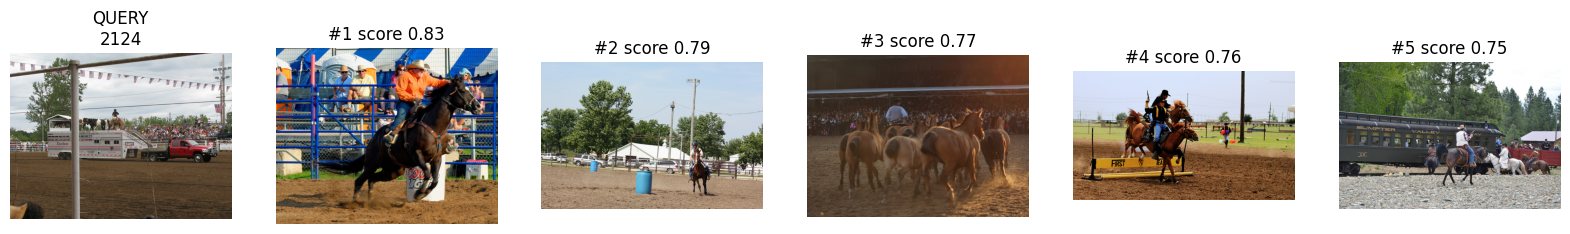

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, ax = plt.subplots(1, 6, figsize=(20, 4))
ax[0].imshow(Image.open(f"{BASE}/validation_images/{val_ids[0]:012d}.jpg"))
ax[0].set_title("QUERY\n" + str(val_ids[0]))
for k, (d, j) in enumerate(zip(D[0], I[0]), 1):
    ax[k].imshow(Image.open(f"{BASE}/train_images/{train_ids[j]:012d}.jpg"))
    ax[k].set_title(f"#{k} score {d:.2f}")
for a in ax: a.axis("off")
plt.savefig(f"{BASE}/retrieval_demo.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install faiss-cpu

import json, numpy as np, faiss
from collections import Counter

BASE = "/content/drive/MyDrive/phase1_data"
EMB = f"{BASE}/embeddings"

train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))
tr_caps   = json.load(open(f"{BASE}/train_captions_processed.json"))
va_caps   = json.load(open(f"{BASE}/validation_captions_processed.json"))
test_refs = json.load(open(f"{BASE}/test_reference_captions.json"))
meta      = json.load(open(f"{BASE}/metadata.json"))
img = np.load(f"{EMB}/kb_image_emb.npy")
val = np.load(f"{EMB}/val_image_emb.npy")
txt = np.load(f"{EMB}/kb_text_emb.npy")
cap_ids = np.load(f"{EMB}/kb_text_caption_ids.npy")

qc = {}
def check(name, ok, detail=""):
    qc[name] = {"passed": bool(ok), "detail": str(detail)}
    print("✅" if ok else "❌", name, "|", detail)

# 1. العدد: embeddings = IDs
check("image embeddings count", img.shape[0] == len(train_ids) and val.shape[0] == len(val_ids),
      f"KB {img.shape}, val {val.shape}")
check("text embeddings count", txt.shape[0] == len(tr_caps), f"{txt.shape} vs {len(tr_caps)} captions")

# 2. NaN / Inf / normalisation
for n, a in [("kb_image", img), ("val_image", val), ("kb_text", txt)]:
    norms = np.linalg.norm(a, axis=1)
    check(f"{n}: no NaN/Inf, unit norm",
          np.isfinite(a).all() and np.allclose(norms, 1, atol=1e-3),
          f"min norm {norms.min():.4f}, max {norms.max():.4f}")

# 3. IDs مكررة
check("duplicate image IDs", all(len(l) == len(set(l)) for l in (train_ids, val_ids, test_ids)),
      f"train {len(train_ids)-len(set(train_ids))}, val {len(val_ids)-len(set(val_ids))}, test {len(test_ids)-len(set(test_ids))}")
check("duplicate caption IDs", len(set(c["caption_id"] for c in tr_caps)) == len(tr_caps), f"{len(tr_caps)} captions")

# 4. captions: 5 لكل صورة، ومطابقة للصور، وترتيب الـ embeddings
for name, caps, ids in [("train", tr_caps, train_ids), ("validation", va_caps, val_ids)]:
    cnt = Counter(c["image_id"] for c in caps)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ image embeddings count | KB (10000, 512), val (100, 512)
✅ text embeddings count | (50000, 384) vs 50000 captions
✅ kb_image: no NaN/Inf, unit norm | min norm 1.0000, max 1.0000
✅ val_image: no NaN/Inf, unit norm | min norm 1.0000, max 1.0000
✅ kb_text: no NaN/Inf, unit norm | min norm 1.0000, max 1.0000
✅ duplicate image IDs | train 0, val 0, test 0
✅ duplicate caption IDs | 50000 captions


In [1]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
qc = json.load(open(f"{BASE}/qc_report.json"))
for name, v in qc.items():
    if isinstance(v, dict):
        print("✅" if v["passed"] else "❌", name, "|", v["detail"])
    else:
        print("ℹ️", name, "|", v)
print("\nAll passed:", all(v["passed"] for v in qc.values() if isinstance(v, dict)))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/qc_report.json'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
EMB = "/content/drive/MyDrive/phase1_data/embeddings"
print(os.path.exists(EMB))
print(sorted(os.listdir(EMB)) if os.path.exists(EMB) else "folder not found")

Mounted at /content/drive
True
['embeddings_documentation.json', 'index_documentation.json', 'kb_image.index', 'kb_image_emb.npy', 'kb_text.index', 'kb_text_caption_ids.npy', 'kb_text_emb.npy', 'val_image_emb.npy']


In [3]:
import json
BASE = "/content/drive/MyDrive/phase1_data"
qc = json.load(open(f"{BASE}/qc_report.json"))
for name, v in qc.items():
    if isinstance(v, dict):
        print("✅" if v["passed"] else "❌", name, "|", v["detail"])
    else:
        print("ℹ️", name, "|", v)
print("\nAll passed:", all(v["passed"] for v in qc.values() if isinstance(v, dict)))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/phase1_data/qc_report.json'

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/phase1_data"
print("folder exists:", os.path.exists(BASE))
print("qc_report.json exists:", os.path.exists(f"{BASE}/qc_report.json"))
print(sorted(f for f in os.listdir(BASE) if f.endswith(".json")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
folder exists: True
qc_report.json exists: False
['audit_documentation.json', 'audit_report.json', 'image_preprocessing_report.json', 'metadata.json', 'metadata_documentation.json', 'test_image_ids.json', 'test_reference_captions.json', 'train_captions.json', 'train_captions_processed.json', 'train_image_ids.json', 'validation_captions.json', 'validation_captions_processed.json', 'validation_image_ids.json']


In [5]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install faiss-cpu

import json, traceback, numpy as np, faiss
from collections import Counter

BASE = "/content/drive/MyDrive/phase1_data"
EMB = f"{BASE}/embeddings"
qc = {}
def check(name, ok, detail=""):
    qc[name] = {"passed": bool(ok), "detail": str(detail)}
    print("✅" if ok else "❌", name, "|", detail)

try:
    train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
    val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
    test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))
    tr_caps   = json.load(open(f"{BASE}/train_captions_processed.json"))
    va_caps   = json.load(open(f"{BASE}/validation_captions_processed.json"))
    test_refs = json.load(open(f"{BASE}/test_reference_captions.json"))
    meta      = json.load(open(f"{BASE}/metadata.json"))
    img = np.load(f"{EMB}/kb_image_emb.npy")
    val = np.load(f"{EMB}/val_image_emb.npy")
    txt = np.load(f"{EMB}/kb_text_emb.npy")
    cap_ids = np.load(f"{EMB}/kb_text_caption_ids.npy")

    check("image embeddings count", img.shape[0] == len(train_ids) and val.shape[0] == len(val_ids), f"KB {img.shape}, val {val.shape}")
    check("text embeddings count", txt.shape[0] == len(tr_caps), f"{txt.shape} vs {len(tr_caps)} captions")
    for n, a in [("kb_image", img), ("val_image", val), ("kb_text", txt)]:
        norms = np.linalg.norm(a, axis=1)
        check(f"{n}: no NaN/Inf, unit norm", np.isfinite(a).all() and np.allclose(norms, 1, atol=1e-3), f"min {norms.min():.4f}, max {norms.max():.4f}")
    check("duplicate image IDs", all(len(l) == len(set(l)) for l in (train_ids, val_ids, test_ids)), "")
    check("duplicate caption IDs", len({c["caption_id"] for c in tr_caps}) == len(tr_caps), f"{len(tr_caps)} captions")

    for name, caps, ids in [("train", tr_caps, train_ids), ("validation", va_caps, val_ids)]:
        cnt = Counter(c["image_id"] for c in caps)
        check(f"{name}: 5 captions per image, IDs in split", set(cnt) == set(ids) and set(cnt.values()) == {5}, f"counts {sorted(set(cnt.values()))}")
    check("text embeddings aligned with captions", [int(x) for x in cap_ids] == [int(c["caption_id"]) for c in tr_caps])
    check("no empty cleaned caption", all(c["caption_clean"].strip() for c in tr_caps + va_caps))

    meta_ids = {m["image_id"] for m in meta}
    check("metadata covers KB + validation", meta_ids

_IncompleteInputError: incomplete input (2461460809.py, line 43)

In [6]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install faiss-cpu

import json, numpy as np, faiss
from collections import Counter

BASE = "/content/drive/MyDrive/phase1_data"
EMB = f"{BASE}/embeddings"
train_ids = json.load(open(f"{BASE}/train_image_ids.json"))
val_ids   = json.load(open(f"{BASE}/validation_image_ids.json"))
test_ids  = json.load(open(f"{BASE}/test_image_ids.json"))
tr_caps   = json.load(open(f"{BASE}/train_captions_processed.json"))
va_caps   = json.load(open(f"{BASE}/validation_captions_processed.json"))
test_refs = json.load(open(f"{BASE}/test_reference_captions.json"))
meta      = json.load(open(f"{BASE}/metadata.json"))
img = np.load(f"{EMB}/kb_image_emb.npy")
val = np.load(f"{EMB}/val_image_emb.npy")
txt = np.load(f"{EMB}/kb_text_emb.npy")
cap_ids = np.load(f"{EMB}/kb_text_caption_ids.npy")

qc = {}
def check(name, ok, detail=""):
    qc[name] = {"passed": bool(ok), "detail": str(detail)}
    print("✅" if ok else "❌", name, "|", detail)

print("loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loaded


In [7]:
check("image embeddings count", img.shape[0] == len(train_ids) and val.shape[0] == len(val_ids), f"KB {img.shape}, val {val.shape}")
check("text embeddings count", txt.shape[0] == len(tr_caps), f"{txt.shape} vs {len(tr_caps)} captions")

for n, a in [("kb_image", img), ("val_image", val), ("kb_text", txt)]:
    norms = np.linalg.norm(a, axis=1)
    check(f"{n}: no NaN/Inf, unit norm", np.isfinite(a).all() and np.allclose(norms, 1, atol=1e-3), f"min {norms.min():.4f}, max {norms.max():.4f}")

check("duplicate image IDs", all(len(l) == len(set(l)) for l in (train_ids, val_ids, test_ids)))
check("duplicate caption IDs", len({c["caption_id"] for c in tr_caps}) == len(tr_caps))

for name, caps, ids in [("train", tr_caps, train_ids), ("validation", va_caps, val_ids)]:
    cnt = Counter(c["image_id"] for c in caps)
    check(f"{name}: 5 captions per image", set(cnt) == set(ids) and set(cnt.values()) == {5})

check("text embeddings aligned with captions", [int(x) for x in cap_ids] == [int(c["caption_id"]) for c in tr_caps])
check("no empty cleaned caption", all(c["caption_clean"].strip() for c in tr_caps + va_caps))

meta_ids = {m["image_id"] for m in meta}
check("metadata covers KB + validation", meta_ids == set(train_ids) | set(val_ids), f"{len(meta_ids)} images")

✅ image embeddings count | KB (10000, 512), val (100, 512)
✅ text embeddings count | (50000, 384) vs 50000 captions
✅ kb_image: no NaN/Inf, unit norm | min 1.0000, max 1.0000
✅ val_image: no NaN/Inf, unit norm | min 1.0000, max 1.0000
✅ kb_text: no NaN/Inf, unit norm | min 1.0000, max 1.0000
✅ duplicate image IDs | 
✅ duplicate caption IDs | 
✅ train: 5 captions per image | 
✅ validation: 5 captions per image | 
✅ text embeddings aligned with captions | 
✅ no empty cleaned caption | 
✅ metadata covers KB + validation | 10100 images


In [8]:
s_tr, s_va, s_te = set(train_ids), set(val_ids), set(test_ids)
check("no ID overlap between splits", not (s_tr & s_va or s_tr & s_te or s_va & s_te))
check("test reference captions match test IDs", {int(k) for k in test_refs} == s_te)

index = faiss.read_index(f"{EMB}/kb_image.index")
check("index size", index.ntotal == len(train_ids), f"{index.ntotal} vectors")

D, I = index.search(img[:200], 2)
check("self-retrieval on 200 KB images", all(k in I[k] for k in range(200)))

Dv, Iv = index.search(val, 5)
check("validation queries never return a validation ID", not any(train_ids[j] in s_va for row in Iv for j in row))

json.dump(qc, open(f"{BASE}/qc_report.json", "w"), indent=2)
print("\nChecks run:", len(qc), "| All passed:", all(v["passed"] for v in qc.values()))

✅ no ID overlap between splits | 
✅ test reference captions match test IDs | 
✅ index size | 10000 vectors
✅ self-retrieval on 200 KB images | 
✅ validation queries never return a validation ID | 

Checks run: 17 | All passed: True


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


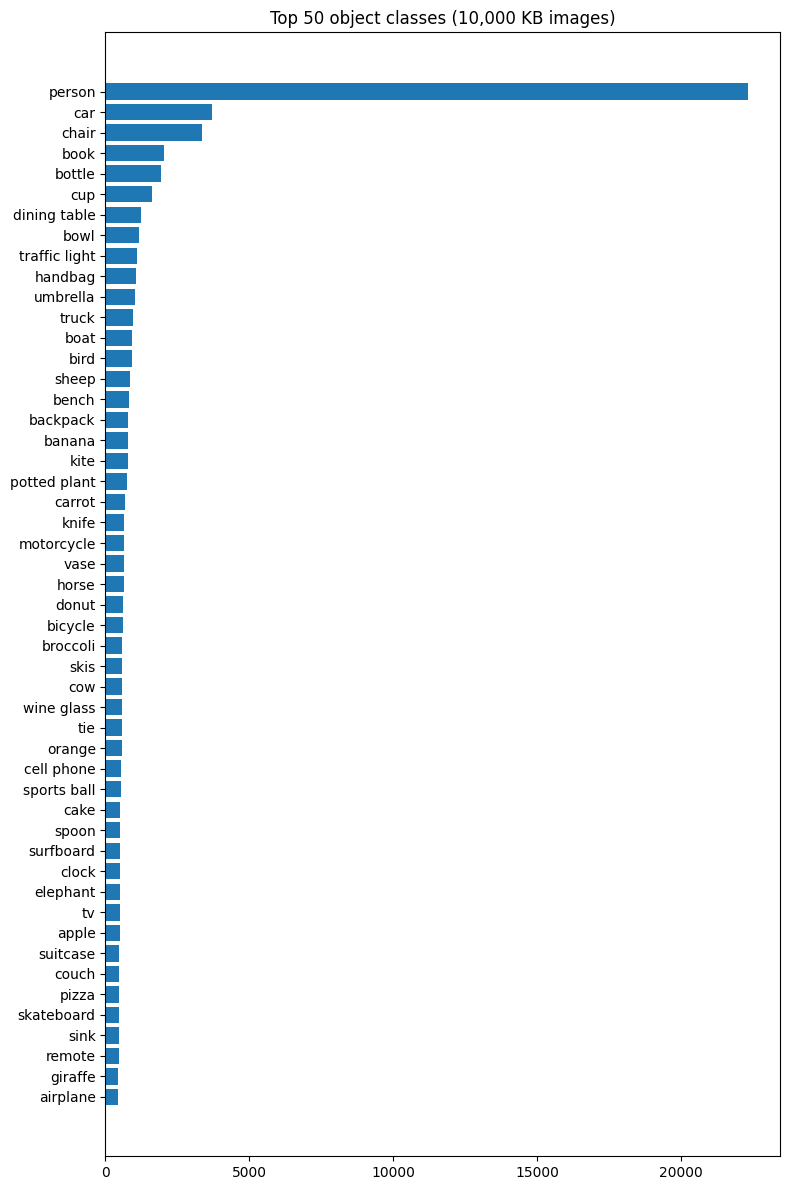

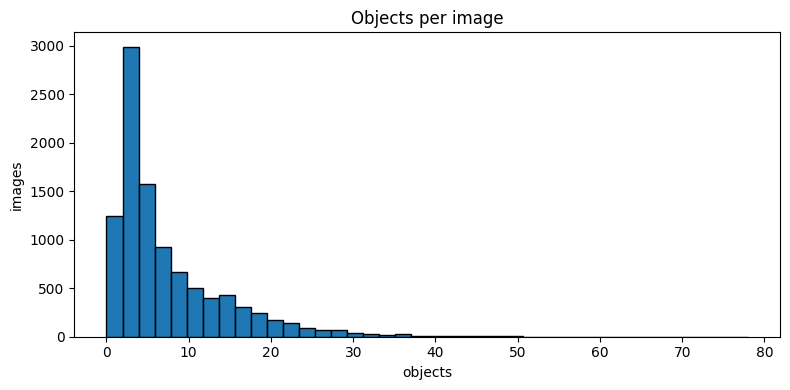

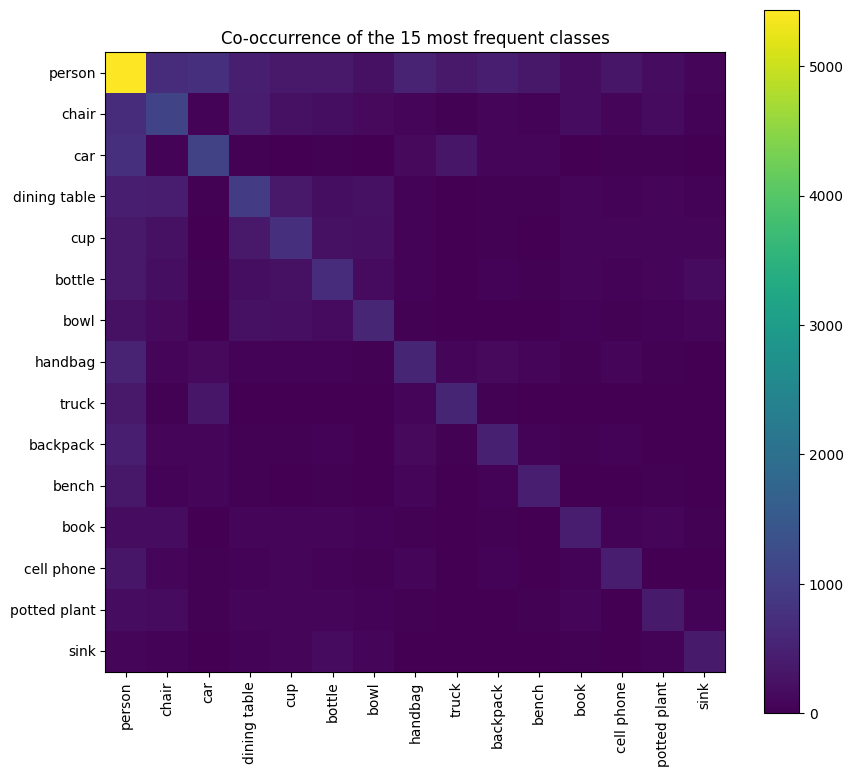

Mean objects/image: 7.23 | median: 4.0
Top 5 classes: [('person', 22329), ('car', 3702), ('chair', 3342), ('book', 2020), ('bottle', 1947)]


In [9]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, numpy as np
import matplotlib.pyplot as plt
from collections import Counter

BASE = "/content/drive/MyDrive/phase1_data"
FIG = f"{BASE}/figures"; os.makedirs(FIG, exist_ok=True)
kb = set(json.load(open(f"{BASE}/train_image_ids.json")))
meta = [m for m in json.load(open(f"{BASE}/metadata.json")) if m["image_id"] in kb]
stats = {"kb_images": len(meta)}

cnt = Counter(o["category"] for m in meta for o in m["objects"])
top = cnt.most_common(50)
plt.figure(figsize=(8, 12))
plt.barh([n for n, _ in top][::-1], [c for _, c in top][::-1])
plt.title("Top 50 object classes (10,000 KB images)")
plt.tight_layout(); plt.savefig(f"{FIG}/top50_classes.png", dpi=150); plt.show()

n_obj = np.array([m["n_objects"] for m in meta])
stats.update({"top50_classes": top, "mean_objects_per_image": float(n_obj.mean()),
              "median_objects_per_image": float(np.median(n_obj)),
              "images_without_objects": int((n_obj == 0).sum())})
plt.figure(figsize=(8, 4)); plt.hist(n_obj, bins=40, edgecolor="black")
plt.title("Objects per image"); plt.xlabel("objects"); plt.ylabel("images")
plt.tight_layout(); plt.savefig(f"{FIG}/objects_per_image.png", dpi=150); plt.show()

names = [n for n, _ in Counter(c for m in meta for c in m["categories"]).most_common(15)]
M = np.zeros((15, 15), int)
for m in meta:
    s = set(m["categories"])
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            if a in s and b in s: M[i, j] += 1
plt.figure(figsize=(9, 8)); plt.imshow(M, cmap="viridis"); plt.colorbar()
plt.xticks(range(15), names, rotation=90); plt.yticks(range(15), names)
plt.title("Co-occurrence of the 15 most frequent classes")
plt.tight_layout(); plt.savefig(f"{FIG}/cooccurrence.png", dpi=150); plt.show()

print("Mean objects/image:", round(n_obj.mean(), 2), "| median:", np.median(n_obj))
print("Top 5 classes:", top[:5])

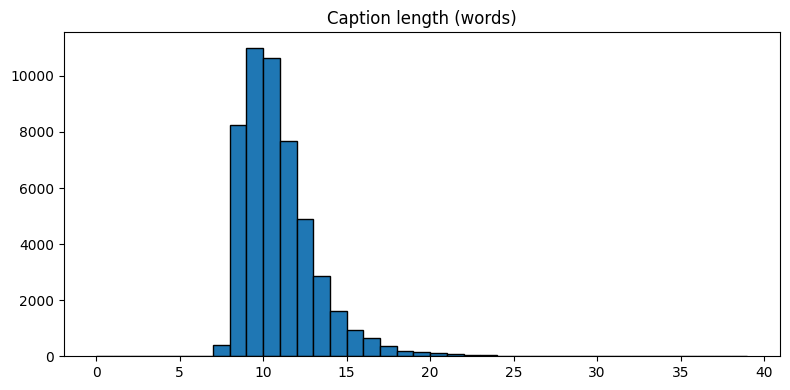

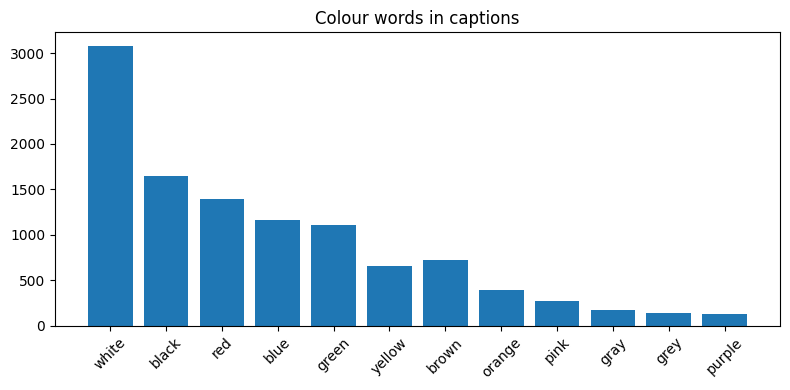

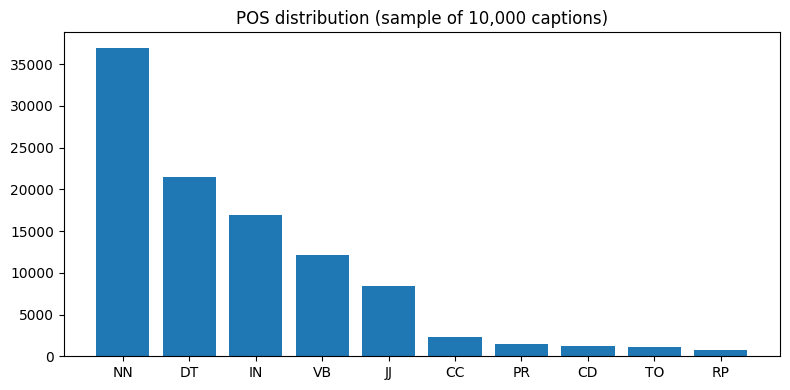

Mean length: 10.46 | vocab: 9682
Context keywords: {'indoor': 7447, 'outdoor': 10001, 'day': 492, 'night': 373}


In [10]:
import re, nltk
caps = json.load(open(f"{BASE}/train_captions_processed.json"))
words = [re.findall(r"[a-z]+", c["caption_clean"]) for c in caps]
lens = np.array([len(w) for w in words])
vocab = Counter(w for ws in words for w in ws)
stats.update({"captions": len(caps), "mean_caption_length": float(lens.mean()),
              "median_caption_length": float(np.median(lens)), "vocab_size": len(vocab)})
plt.figure(figsize=(8, 4)); plt.hist(lens, bins=range(0, 40), edgecolor="black")
plt.title("Caption length (words)"); plt.tight_layout()
plt.savefig(f"{FIG}/caption_length.png", dpi=150); plt.show()

colors = ["white","black","red","blue","green","yellow","brown","orange","pink","gray","grey","purple"]
col = {c: vocab[c] for c in colors}
plt.figure(figsize=(8, 4)); plt.bar(col.keys(), col.values()); plt.xticks(rotation=45)
plt.title("Colour words in captions"); plt.tight_layout()
plt.savefig(f"{FIG}/colors.png", dpi=150); plt.show()
stats["colour_word_counts"] = col

ctx = {"indoor": ["kitchen","bathroom","bedroom","room","table","couch","inside","indoor"],
       "outdoor": ["street","beach","field","park","outside","road","grass","snow","mountain"],
       "day": ["sunny","daytime","day"], "night": ["night","dark","evening"]}
stats["context_keyword_counts"] = {k: sum(vocab[w] for w in v) for k, v in ctx.items()}

for p in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]:
    nltk.download(p, quiet=True)
tags = Counter()
for ws in words[:10000]:
    for _, t in nltk.pos_tag(ws): tags[t[:2]] += 1
plt.figure(figsize=(8, 4)); plt.bar(*zip(*tags.most_common(10)))
plt.title("POS distribution (sample of 10,000 captions)"); plt.tight_layout()
plt.savefig(f"{FIG}/pos.png", dpi=150); plt.show()
stats["pos_top10_sample"] = tags.most_common(10)

json.dump(stats, open(f"{BASE}/dataset_stats.json", "w"), indent=2)
print("Mean length:", round(lens.mean(), 2), "| vocab:", len(vocab))
print("Context keywords:", stats["context_keyword_counts"])